# Assignment 3: Machine Learning (CSE343/CSE543)
## Instructions
## ✅ Rename the filename with your roll number. E.g. if your roll number is `MT22018` then rename the file `MT22018_a3.ipynb` before submitting.
## ✅ Write code only in the sections marked with `### YOUR CODE HERE`. No, you can NOT write code anywhere else.
## ✅ Do NOT install or import any other libraries beyond what is imported below.
## ❌ Do not modify any other function or class definitions; doing so may lead to the autograder failing to judge your submission, resulting in a zero.
## ❌ Deleting or adding new cells may lead to the autograder failing to judge your submission, resulting in a zero. Even if a cell is empty, do NOT delete it.
## ❌ Do NOT use sklearn for implementing the core algorithms in Q1 (cross-validation loop), Q3 (neural network), or Q4 (SVM). sklearn is allowed only for data generation and metrics.

**Total Marks: 14**
- Q1: K-Fold Cross-Validation (3 marks)
- Q2: Bias-Variance Tradeoff (2 marks)
- Q3: Neural Network from Scratch (5 marks)
- Q4: Support Vector Machine (4 marks)

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, make_circles, make_blobs, load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.base import clone
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

---

# Q1: K-Fold Cross-Validation from Scratch (3 marks)

Implement k-fold cross-validation **without using sklearn's KFold or cross_val_score**. You may use sklearn models as classifiers but the splitting and CV loop logic must be yours.

### Part A (1 mark): `create_folds`
Implement a function that splits data indices into k folds. Each sample must appear in exactly one validation fold.

### Part B (1 mark): `run_cv`
Implement a function that performs k-fold CV given a model, data, and k. Returns a dictionary with per-fold scores and summary statistics.

### Part C (1 mark): `create_stratified_folds`
Same as Part A but preserves the class distribution in each fold. For an imbalanced dataset, each fold should have approximately the same class ratio as the full dataset (within ±5%).

In [7]:
def create_folds(X, y, k):
    """
    Split dataset indices into k folds.

    Args:
        X: numpy array of shape (n_samples, n_features)
        y: numpy array of shape (n_samples,)
        k: int, number of folds

    Returns:
        folds: list of k tuples (train_indices, val_indices)
               where each is a numpy array of indices
    """
    ### YOUR CODE HERE
    indices = np.arange(len(X))
    np.random.shuffle(indices)
    
    fold_sizes = len(X) // k
    folds = []
    
    for i in range(k):
        start = i * fold_sizes
        end = start + fold_sizes if i != k - 1 else len(X)
        
        val_indices = indices[start:end]
        train_indices = np.concatenate((indices[:start], indices[end:]))
        
        folds.append((train_indices, val_indices))
    
    return folds
    


def run_cv(model_class, X, y, k=5):
    """
    Perform k-fold cross-validation.

    Args:
        model_class: a sklearn-compatible model instance (has fit/predict)
        X: numpy array (n_samples, n_features)
        y: numpy array (n_samples,)
        k: int, number of folds

    Returns:
        dict with keys:
            'fold_scores': list of k float accuracy scores
            'mean_score': float, mean of fold scores
            'std_score': float, std of fold scores
    """
    ### YOUR CODE HERE
    folds = create_folds(X, y, k)
    
    fold_scores = []
    
    for train_idx, val_idx in folds:
        model = clone(model_class)
        
        X_train, X_val = X[train_idx], X[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]
        
        model.fit(X_train, y_train)
        y_pred = model.predict(X_val)
        
        acc = accuracy_score(y_val, y_pred)
        fold_scores.append(acc)
    
    return {
        'fold_scores': fold_scores,
        'mean_score': np.mean(fold_scores),
        'std_score': np.std(fold_scores)
    }
    


def create_stratified_folds(X, y, k):
    """
    Split dataset into k stratified folds (class proportions preserved).

    Args:
        X: numpy array (n_samples, n_features)
        y: numpy array (n_samples,)
        k: int, number of folds

    Returns:
        folds: list of k tuples (train_indices, val_indices)
    """
    ### YOUR CODE HERE
    unique_classes = np.unique(y)
    
    class_indices = {cls: np.where(y == cls)[0] for cls in unique_classes}
    
    # Shuffle indices of each class
    for cls in unique_classes:
        np.random.shuffle(class_indices[cls])
    
    folds = [[] for _ in range(k)]
    
    # Distribute samples of each class into folds
    for cls in unique_classes:
        cls_idx = class_indices[cls]
        
        for i, idx in enumerate(cls_idx):
            folds[i % k].append(idx)
    
    # Convert to (train, val) format
    final_folds = []
    
    for i in range(k):
        val_indices = np.array(folds[i])
        train_indices = np.array(
            [idx for j in range(k) if j != i for idx in folds[j]]
        )
        
        final_folds.append((train_indices, val_indices))
    
    return final_folds
    

In [8]:
# DO NOT MODIFY — Autograder test for Q1 Part A

In [9]:
# DO NOT MODIFY — Autograder test for Q1 Part B

In [10]:
# DO NOT MODIFY — Autograder test for Q1 Part C (Stratified)

# Q2: Bias-Variance Tradeoff (2 marks)

Implement the bootstrap-based bias-variance decomposition for regression.

**Background:** For a regression model, the expected prediction error can be decomposed as:
$\text{Error} = \text{Bias}^2 + \text{Variance} + \text{Irreducible Noise}$

Where:
- $\text{Bias}^2 = \frac{1}{n}\sum_i (\bar{f}(x_i) - y_i)^2$ where $\bar{f}(x_i)$ is the mean prediction across bootstraps
- $\text{Variance} = \frac{1}{n}\sum_i \text{Var}[\hat{f}(x_i)]$ across bootstrap predictions
- $\text{Total Error} = \frac{1}{n}\sum_i \mathbb{E}[(\hat{f}(x_i) - y_i)^2]$ averaged across bootstraps

### Part A (1 mark): `bootstrap_train_predict`
Train a model on multiple bootstrap samples and collect predictions on a fixed test set.

### Part B (1 mark): `compute_bias_variance`
Compute the bias², variance, and total error from the predictions matrix.

After implementing both, plot bias² and variance vs polynomial degree (1 to 15) — this plot is for your understanding and is NOT graded.

In [11]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline


def bootstrap_train_predict(model_class, X_train, y_train, X_test, n_bootstraps=50):
    """
    Train model on bootstrap samples, predict on fixed test set.

    Args:
        model_class: sklearn model instance (will be cloned for each bootstrap)
        X_train: (n_train, n_features)
        y_train: (n_train,)
        X_test: (n_test, n_features)
        n_bootstraps: int

    Returns:
        predictions: numpy array of shape (n_bootstraps, n_test_samples)
    """
    ### YOUR CODE HERE
    n_train = X_train.shape[0]
    predictions = []

    for _ in range(n_bootstraps):
        # Sample with replacement
        indices = np.random.choice(n_train, size=n_train, replace=True)
        
        X_sample = X_train[indices]
        y_sample = y_train[indices]
        
        # Clone model to avoid overwrite
        model = clone(model_class)
        model.fit(X_sample, y_sample)
        
        y_pred = model.predict(X_test)
        predictions.append(y_pred)
    
    return np.array(predictions)


def compute_bias_variance(predictions, y_test):
    """
    Compute bias-variance decomposition from predictions matrix.

    Args:
        predictions: numpy array of shape (n_bootstraps, n_test_samples)
        y_test: numpy array of shape (n_test_samples,)

    Returns:
        dict with keys:
            'bias_squared': float
            'variance': float
            'total_error': float
    """
    ### YOUR CODE HERE
    # Mean prediction across bootstraps
    mean_pred = np.mean(predictions, axis=0)
    
    # Bias^2
    bias_squared = np.mean((mean_pred - y_test) ** 2)
    
    # Variance
    variance = np.mean(np.var(predictions, axis=0))
    
    # Total error
    total_error = np.mean((predictions - y_test) ** 2)
    
    return {
        'bias_squared': bias_squared,
        'variance': variance,
        'total_error': total_error
    }

In [12]:
# DO NOT MODIFY — Autograder test for Q2 Part A

In [13]:
# DO NOT MODIFY — Autograder test for Q2 Part B

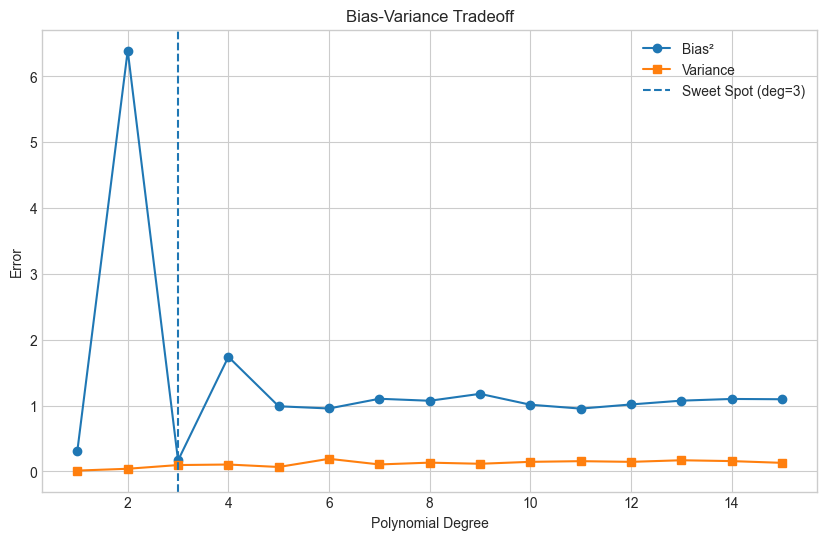

In [ ]:
# Plot bias-variance tradeoff for polynomial degrees 1-15
# This cell is for your understanding and is NOT graded

### YOUR CODE HERE
# Generate synthetic regression data
np.random.seed(42)
X = np.linspace(-3, 3, 200).reshape(-1, 1)
y = np.sin(X).ravel() + np.random.normal(0, 0.3, size=X.shape[0])

# Train-test split
split = int(0.7 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

bias_list = []
var_list = []

degrees = range(1, 16)

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

for d in degrees:
    model = make_pipeline(
        PolynomialFeatures(degree=d),
        StandardScaler(),
        Ridge(alpha=1.0)
    )
    
    preds = bootstrap_train_predict(
        model, X_train, y_train, X_test, n_bootstraps=100  
    )
    
    stats = compute_bias_variance(preds, y_test)
    
    bias_list.append(stats['bias_squared'])
    var_list.append(stats['variance'])

# Plot
plt.figure(figsize=(10, 6))

plt.plot(degrees, bias_list, marker='o', label='Bias²')
plt.plot(degrees, var_list, marker='s', label='Variance')

# Highlight minimum point (sweet spot)
total = np.array(bias_list) + np.array(var_list)
best_degree = degrees[np.argmin(total)]

plt.axvline(best_degree, linestyle='--', label=f'Sweet Spot (deg={best_degree})')

plt.xlabel('Polynomial Degree')
plt.ylabel('Error')
plt.title('Bias-Variance Tradeoff')
plt.legend()
plt.grid(True)

plt.show()

# Q3: Neural Network from Scratch (5 marks)

Implement a feedforward neural network using **only NumPy**. No PyTorch, TensorFlow, or sklearn neural network classes allowed.

**Architecture Requirements:**
- Configurable hidden layers via `layer_dims` parameter (e.g., `[2, 64, 32, 1]`)
- ReLU activation for hidden layers
- Sigmoid activation for output layer (binary classification)
- Binary Cross-Entropy loss
- Full-batch gradient descent

**Grading Breakdown:**
1. Weight initialization & shapes (0.5 marks)
2. Forward pass (1 mark)
3. Backpropagation — gradient computation (1.5 marks)
4. Training loop (0.5 marks)
5. Accuracy on `make_moons` dataset (1.5 marks) — bracket grading:

| Accuracy | Score |
|----------|-------|
| > 93%    | 1.5/1.5 (0.5 + 0.5 + 0.5) |
| 88–93%   | 1.0/1.5 (0.5 + 0.5)       |
| 82–88%   | 0.5/1.5 (0.5)             |
| < 82%    | 0/1.5                     |

**Mathematical Reference:**

Forward pass:
$Z^{[l]} = W^{[l]T} A^{[l-1]} + b^{[l]}$
$A^{[l]} = g^{[l]}(Z^{[l]})$

where $g$ is ReLU for hidden layers and Sigmoid for the output layer.

Binary Cross-Entropy Loss:
$\mathcal{L} = -\frac{1}{m}\sum_{i=1}^{m}[y_i \log(\hat{y}_i) + (1-y_i)\log(1-\hat{y}_i)]$

Backpropagation (output layer):
$dZ^{[L]} = A^{[L]} - Y$
$dW^{[L]} = \frac{1}{m} dZ^{[L]} A^{[L-1]T}$
$db^{[L]} = \frac{1}{m} \sum dZ^{[L]}$

Backpropagation (hidden layers):
$dA^{[l]} = W^{[l+1]} dZ^{[l+1]}$
$dZ^{[l]} = dA^{[l]} * g'^{[l]}(Z^{[l]})$

In [15]:
class NeuralNetwork:
    """
    Feedforward Neural Network for binary classification.
    Uses only NumPy. ReLU hidden activations, Sigmoid output.
    """

    def __init__(self, layer_dims):
        """
        Args:
            layer_dims: list of ints, e.g. [2, 64, 32, 1]
                        first element = input features
                        last element = output (1 for binary classification)
        """
        ### YOUR CODE HERE
        self.layer_dims = layer_dims
        self.L = len(layer_dims) - 1  # number of layers
        self.params = {}
        self._cache = {}

        # He initialization (important for ReLU)
        for l in range(1, len(layer_dims)):
            self.params[f"W{l}"] = np.random.randn(layer_dims[l-1], layer_dims[l]) * np.sqrt(2. / layer_dims[l-1])
            self.params[f"b{l}"] = np.zeros((1, layer_dims[l]))

    def _relu(self, Z):
        """ReLU activation."""
        ### YOUR CODE HERE
        return np.maximum(0, Z)

    def _relu_derivative(self, Z):
        """Derivative of ReLU."""
        ### YOUR CODE HERE
        return (Z > 0).astype(float)

    def _sigmoid(self, Z):
        """Sigmoid activation."""
        ### YOUR CODE HERE
        Z = np.clip(Z, -500, 500)   # prevents overflow
        return 1 / (1 + np.exp(-Z))

    def forward(self, X):
        """
        Forward pass through the network.

        Args:
            X: numpy array of shape (n_samples, n_features)

        Returns:
            output: numpy array of shape (n_samples, 1) — predicted probabilities

        Must store intermediate values in self._cache for use in backward().
        Cache should contain:
            'A0': input X
            'Z1', 'A1': pre-activation and activation for layer 1
            'Z2', 'A2': pre-activation and activation for layer 2
            ... etc.
        """
        ### YOUR CODE HERE
        A = X
        self._cache["A0"] = X

        for l in range(1, self.L + 1):
            W = self.params[f"W{l}"]
            b = self.params[f"b{l}"]

            Z = A @ W + b
            self._cache[f"Z{l}"] = Z

            if l == self.L:
                A = self._sigmoid(Z)
            else:
                A = self._relu(Z)

            self._cache[f"A{l}"] = A

        return A

    def compute_loss(self, y_pred, y_true):
        """
        Binary cross-entropy loss.

        Args:
            y_pred: (n_samples, 1)
            y_true: (n_samples, 1)

        Returns:
            loss: float
        """
        ### YOUR CODE HERE
        m = y_true.shape[0]
        eps = 1e-8  # to avoid log(0)

        loss = -np.mean(
            y_true * np.log(y_pred + eps) +
            (1 - y_true) * np.log(1 - y_pred + eps)
        )
        return loss

    def backward(self, y_true, learning_rate=0.01):
        """
        Backpropagation: compute gradients and update weights.

        Args:
            y_true: numpy array of shape (n_samples, 1)
            learning_rate: float

        Returns:
            gradients: dict with keys 'dW1', 'db1', 'dW2', 'db2', etc.
                       for inspection/testing purposes
        """
        ### YOUR CODE HERE
        grads = {}
        m = y_true.shape[0]

        A_final = self._cache[f"A{self.L}"]
        dZ = A_final - y_true  # output layer gradient

        for l in reversed(range(1, self.L + 1)):
            A_prev = self._cache[f"A{l-1}"]
            W = self.params[f"W{l}"]

            dW = (A_prev.T @ dZ) / m
            db = np.sum(dZ, axis=0, keepdims=True) / m

            grads[f"dW{l}"] = dW
            grads[f"db{l}"] = db

            if l > 1:
                dA_prev = dZ @ W.T
                Z_prev = self._cache[f"Z{l-1}"]
                dZ = dA_prev * self._relu_derivative(Z_prev)

            # Update parameters
            self.params[f"W{l}"] -= learning_rate * dW
            self.params[f"b{l}"] -= learning_rate * db

        return grads

    def train(self, X, y, epochs=1000, learning_rate=0.01):
        """
        Train the network.

        Args:
            X: (n_samples, n_features)
            y: (n_samples,) or (n_samples, 1)
            epochs: int
            learning_rate: float

        Returns:
            dict with keys:
                'losses': list of float loss values per epoch
                'final_loss': float
        """
        ### YOUR CODE HERE
        if y.ndim == 1:
            y = y.reshape(-1, 1)

        losses = []

        for epoch in range(epochs):
            y_pred = self.forward(X)
            loss = self.compute_loss(y_pred, y)
            self.backward(y, learning_rate)

            losses.append(loss)

        return {
            "losses": losses,
            "final_loss": losses[-1]
        }

    def predict(self, X):
        """
        Predict class labels.

        Args:
            X: (n_samples, n_features)

        Returns:
            predictions: (n_samples,) array of 0s and 1s
        """
        ### YOUR CODE HERE
        probs = self.forward(X)
        return (probs > 0.5).astype(int).flatten()

In [16]:
# DO NOT MODIFY — Autograder test for Q3: Weight initialization

In [17]:
# DO NOT MODIFY — Autograder test for Q3: Forward pass

In [18]:
# DO NOT MODIFY — Autograder test for Q3: Backpropagation (gradient check)

In [19]:
# DO NOT MODIFY — Autograder test for Q3: Training loop

In [20]:
# DO NOT MODIFY — This cell trains your NN and computes accuracy for bracket grading
np.random.seed(42)
_X_moon, _y_moon = make_moons(n_samples=800, noise=0.3, random_state=42)
_scaler = StandardScaler()
_X_moon = _scaler.fit_transform(_X_moon)
_X_m_train, _X_m_test, _y_m_train, _y_m_test = train_test_split(_X_moon, _y_moon, test_size=0.2, random_state=42)

_nn5 = NeuralNetwork([2, 64, 32, 1])
_nn5.train(_X_m_train, _y_m_train, epochs=1000, learning_rate=0.1)
_y_m_pred = _nn5.predict(_X_m_test)
_nn_acc = accuracy_score(_y_m_test, _y_m_pred)
print(f"[Q3e] Neural Network accuracy on make_moons: {_nn_acc:.4f}")

[Q3e] Neural Network accuracy on make_moons: 0.9187


In [21]:
# DO NOT MODIFY — Q3 Test

In [22]:
# DO NOT MODIFY — Q3 Test

In [23]:
# DO NOT MODIFY — Q3 Test

# Q4: Support Vector Machine with Hinge Loss (4 marks)

Implement a linear SVM using subgradient descent on the hinge loss. Then implement an RBF kernel function.

**sklearn is NOT allowed for the SVM implementation.** You may use sklearn for data generation and evaluation metrics only.

**Mathematical Reference:**

Hinge Loss (primal SVM objective):
$\mathcal{L}(w, b) = \frac{1}{2}||w||^2 + C \sum_{i=1}^{m} \max(0, 1 - y_i(w^T x_i + b))$

Subgradient for $w$:
$\nabla_w \mathcal{L} = w - C \sum_{i: y_i(w^T x_i + b) < 1} y_i x_i$

Subgradient for $b$:
$\nabla_b \mathcal{L} = -C \sum_{i: y_i(w^T x_i + b) < 1} y_i$

RBF Kernel:
$K(x_i, x_j) = \exp\left(-\gamma ||x_i - x_j||^2\right)$

**Note:** The labels must be +1 and -1 (not 0 and 1) for the hinge loss formulation.

### Grading:
1. `hinge_loss` function (0.5 marks)
2. `compute_svm_gradients` function (0.5 marks)
3. `SVMClassifier.fit` — convergence (1 mark)
4. `rbf_kernel` function (0.5 marks)
5. `SVMClassifier.predict` + accuracy bracket (1.5 marks):

| Accuracy | Score |
|----------|-------|
| > 90%    | 1.5/1.5 (0.5 + 0.5 + 0.5) |
| 84–90%   | 1.0/1.5 (0.5 + 0.5)       |
| 78–84%   | 0.5/1.5 (0.5)             |
| < 78%    | 0/1.5                     |

In [24]:
def hinge_loss(X, y, w, b, C=1.0):
    """
    Compute SVM hinge loss.

    Args:
        X: (n_samples, n_features)
        y: (n_samples,) with values in {-1, +1}
        w: (n_features,)
        b: float
        C: regularization parameter

    Returns:
        loss: float
    """
    ### YOUR CODE HERE
    margins = y * (X @ w + b)
    m = X.shape[0]
    return 0.5 * np.dot(w, w) + (C / m) * np.sum(np.maximum(0, 1 - margins))


def compute_svm_gradients(X, y, w, b, C=1.0):
    """
    Compute subgradients of hinge loss w.r.t. w and b.

    Args:
        X: (n_samples, n_features)
        y: (n_samples,) with values in {-1, +1}
        w: (n_features,)
        b: float
        C: regularization parameter

    Returns:
        dw: (n_features,) gradient w.r.t. w
        db: float, gradient w.r.t. b
    """
    ### YOUR CODE HERE
    margins = y * (X @ w + b)
    mask = margins < 1

    dw = w - C * np.sum((y[mask][:, None] * X[mask]), axis=0)
    db = -C * np.sum(y[mask])

    return dw, db


def rbf_kernel(X1, X2, gamma=1.0):
    """
    Compute RBF (Gaussian) kernel matrix.

    Args:
        X1: (n1, n_features)
        X2: (n2, n_features)
        gamma: float, kernel bandwidth parameter

    Returns:
        K: (n1, n2) kernel matrix
    """
    ### YOUR CODE HERE
    X1_sq = np.sum(X1**2, axis=1).reshape(-1, 1)
    X2_sq = np.sum(X2**2, axis=1).reshape(1, -1)
    dist_sq = X1_sq + X2_sq - 2 * (X1 @ X2.T)
    return np.exp(-gamma * dist_sq)


class SVMClassifier:
    """Linear SVM using subgradient descent on hinge loss."""

    def __init__(self, C=1.0, learning_rate=0.01, epochs=1000):
        ### YOUR CODE HERE
        self.C = C
        self.lr = learning_rate
        self.epochs = epochs
        self.gamma = 1.0
        self.w = None
        self.b = None
        self.X_train = None

    def fit(self, X, y):
        """
        Train SVM using subgradient descent.
        Labels y must be in {-1, +1}.

        Args:
            X: (n_samples, n_features)
            y: (n_samples,) values in {-1, +1}

        Returns:
            dict with key 'losses': list of loss values per epoch
        """
        ### YOUR CODE HERE
        self.X_train = X

        # Transform using RBF kernel
        K = rbf_kernel(X, X, gamma=self.gamma)

        n_features = K.shape[1]
        self.w = np.zeros(n_features)
        self.b = 0.0

        losses = []

        for _ in range(self.epochs):
            dw, db = compute_svm_gradients(K, y, self.w, self.b, self.C)

            self.w -= self.lr * dw
            self.b -= self.lr * db

            loss = hinge_loss(K, y, self.w, self.b, self.C)
            losses.append(loss)

        return {'losses': losses}

    def predict(self, X):
        """
        Predict class labels {-1, +1}.

        Args:
            X: (n_samples, n_features)

        Returns:
            predictions: (n_samples,) array of -1 and +1
        """
        ### YOUR CODE HERE
        K = rbf_kernel(X, self.X_train, gamma=self.gamma)
        scores = K @ self.w + self.b
        return np.where(scores >= 0, 1, -1)

In [25]:
# DO NOT MODIFY — Autograder test for Q4: Hinge loss

In [26]:
# DO NOT MODIFY — Autograder test for Q4: Gradients (numerical check)

In [27]:
# DO NOT MODIFY — Autograder test for Q4: Fit + convergence

In [28]:
# DO NOT MODIFY — Autograder test for Q4: RBF kernel

In [29]:
# DO NOT MODIFY — This cell trains your SVM and computes accuracy for bracket grading
np.random.seed(42)
_X_svm_acc, _y_svm_acc = make_moons(n_samples=600, noise=0.25, random_state=7)
_y_svm_acc = 2 * _y_svm_acc - 1  # Convert 0/1 to -1/+1
_scaler_svm = StandardScaler()
_X_svm_acc = _scaler_svm.fit_transform(_X_svm_acc)
_X_s_train, _X_s_test, _y_s_train, _y_s_test = train_test_split(_X_svm_acc, _y_svm_acc, test_size=0.2, random_state=42)

_svm_final = SVMClassifier(C=0.5, learning_rate=0.0005, epochs=2000)
_svm_final.fit(_X_s_train, _y_s_train)
_y_s_pred = _svm_final.predict(_X_s_test)
_svm_acc = accuracy_score(_y_s_test, _y_s_pred)
print(f"[Q4e] SVM accuracy: {_svm_acc:.4f}")

[Q4e] SVM accuracy: 0.9667


In [30]:
# DO NOT MODIFY — Q4 Test

In [31]:
# DO NOT MODIFY — Q4 Test

In [32]:
# DO NOT MODIFY — Q4 Test

---